In [1]:

import pandas as pd
from pathlib import Path

# Locate the Excel dataset
file_path = Path("../data/raw/Online Retail.xlsx")

# Load the data
df = pd.read_excel(file_path)

# Display basic information
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

# Display the first five records
display(df.head())


Dataset loaded successfully!
Number of rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:

# Display all column names
print("Column names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

# Count missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     1350

In [3]:

# Make a copy of the original dataset
clean_df = df.copy()

# 1. Remove exact duplicate rows
clean_df = clean_df.drop_duplicates()

# 2. Convert columns to appropriate data types
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"], errors="coerce"
)

clean_df["CustomerID"] = clean_df["CustomerID"].astype("Int64")

# 3. Remove rows with missing essential transaction information
clean_df = clean_df.dropna(
    subset=["InvoiceNo", "StockCode", "InvoiceDate",
            "Quantity", "UnitPrice"]
)

# 4. Calculate transaction revenue
clean_df["Revenue"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

# 5. Create a cancellation indicator
clean_df["IsCancelled"] = (
    clean_df["InvoiceNo"].astype(str).str.startswith("C")
)

# Display the results
print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df.drop_duplicates()))
print("Cleaned rows:", len(clean_df))
print("Missing customer IDs:", clean_df["CustomerID"].isna().sum())
print("Cancellation records:", clean_df["IsCancelled"].sum())

display(clean_df.head())


Original rows: 541909
Rows after removing duplicates: 536641
Cleaned rows: 536641
Missing customer IDs: 135037
Cancellation records: 9251


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancelled
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False


In [4]:

# Use completed, non-cancellation transactions
sales_df = clean_df[
    (~clean_df["IsCancelled"]) &
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

# Overall business metrics
total_revenue = sales_df["Revenue"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
total_customers = sales_df["CustomerID"].nunique()
total_products = sales_df["StockCode"].nunique()

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")


Total Revenue: £10,642,110.80
Total Orders: 19,960
Unique Customers: 4,338
Unique Products: 3,922


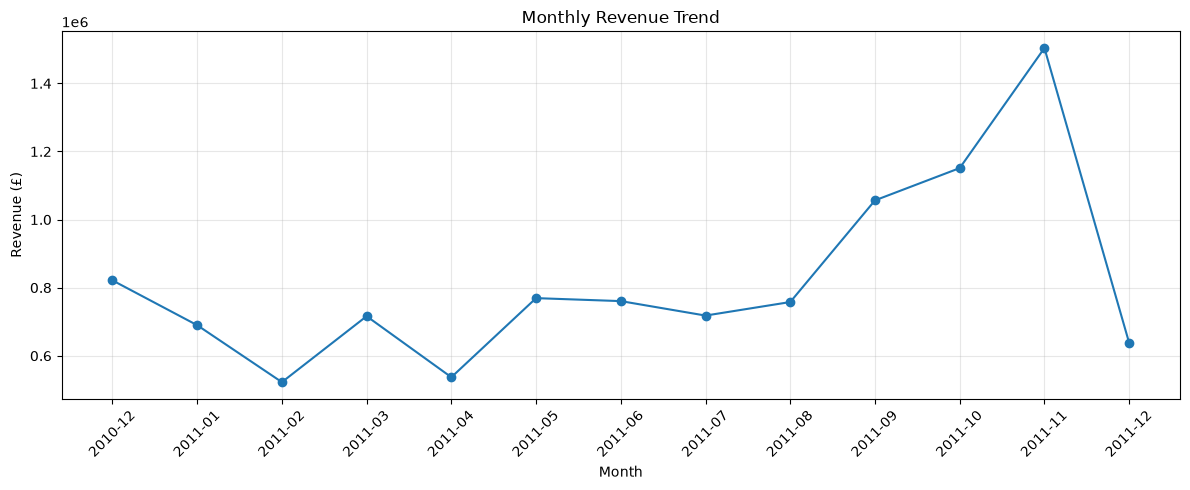

,Month,Revenue
0,2010-12,821452.730
1,2011-01,689811.610
2,2011-02,522545.560
3,2011-03,716215.260
4,2011-04,536968.491
5,2011-05,769296.610
6,2011-06,760547.010
7,2011-07,718076.121
8,2011-08,757841.380
9,2011-09,1056435.192


In [5]:

import matplotlib.pyplot as plt

# Extract the month from the invoice date
sales_df["Month"] = (
    sales_df["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_sales = (
    sales_df.groupby("Month")["Revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_sales)


,Description,Units_Sold,Revenue
0,DOTCOM POSTAGE,706,206248.77
1,REGENCY CAKESTAND 3 TIER,13851,174156.54
2,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60
3,WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72
4,PARTY BUNTING,18283,99445.23
5,JUMBO BAG RED RETROSPOT,48371,94159.81
6,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92
7,POSTAGE,3150,78101.88
8,Manual,6985,77752.82
9,RABBIT NIGHT LIGHT,30739,66870.03


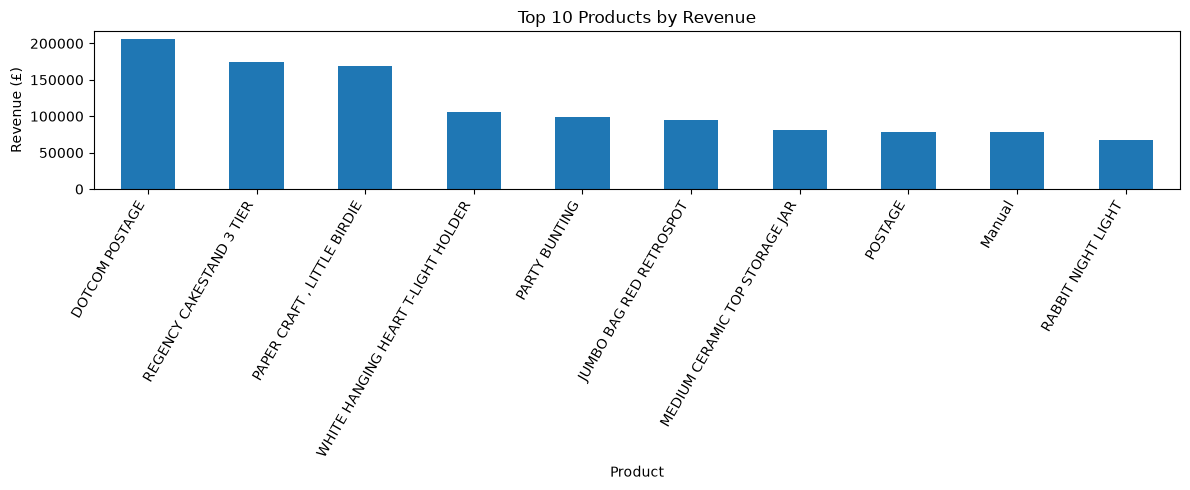

In [6]:

top_products = (
    sales_df.groupby("Description")
    .agg(
        Units_Sold=("Quantity", "sum"),
        Revenue=("Revenue", "sum")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
    .reset_index()
)

display(top_products)

top_products.plot(
    x="Description",
    y="Revenue",
    kind="bar",
    figsize=(12, 5),
    legend=False
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Product")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


In [7]:

customer_summary = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Total_Spent=("Revenue", "sum"),
        Orders=("InvoiceNo", "nunique"),
        Total_Units=("Quantity", "sum"),
        Last_Purchase=("InvoiceDate", "max")
    )
    .sort_values("Total_Spent", ascending=False)
    .reset_index()
)

print("Top 10 customers by spending:")
display(customer_summary.head(10))


Top 10 customers by spending:


,CustomerID,Total_Spent,Orders,Total_Units,Last_Purchase
0,14646,280206.02,73,196915,2011-12-08 12:12:00
1,18102,259657.30,60,64124,2011-12-09 11:50:00
2,17450,194390.79,46,69973,2011-12-01 13:29:00
3,16446,168472.50,2,80997,2011-12-09 09:15:00
4,14911,143711.17,201,80240,2011-12-08 15:54:00
5,12415,124914.53,21,77374,2011-11-15 14:22:00
6,14156,117210.08,55,57768,2011-11-30 10:54:00
7,17511,91062.38,31,64549,2011-12-07 10:12:00
8,16029,80850.84,63,40108,2011-11-01 10:27:00
9,12346,77183.60,1,74215,2011-01-18 10:01:00


,Customer_Type,Number_of_Customers
0,Repeat Customer,2845
1,One-Time Customer,1493


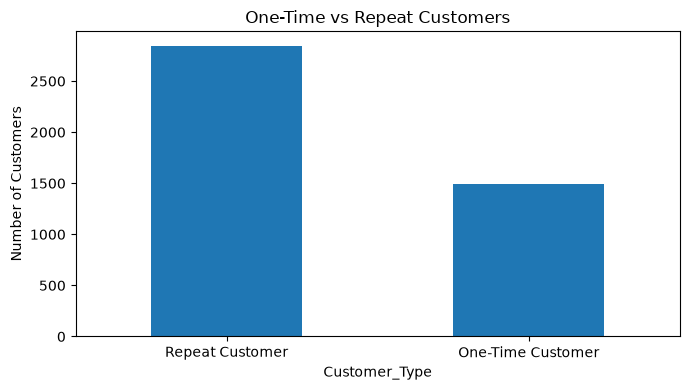

In [8]:

customer_summary["Customer_Type"] = customer_summary["Orders"].apply(
    lambda orders: "Repeat Customer"
    if orders > 1
    else "One-Time Customer"
)

customer_types = (
    customer_summary["Customer_Type"]
    .value_counts()
    .rename_axis("Customer_Type")
    .reset_index(name="Number_of_Customers")
)

display(customer_types)

customer_types.plot(
    x="Customer_Type",
    y="Number_of_Customers",
    kind="bar",
    figsize=(7, 4),
    legend=False
)

plt.title("One-Time vs Repeat Customers")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [9]:

import pandas as pd
import numpy as np

# Set the reference date to one day after the last recorded transaction
reference_date = sales_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Build the RFM table using identified customers
rfm = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda x:
                 (reference_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

# Create scores from 1 to 5
# Recency: fewer days since purchase is better
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency and Monetary: higher values are better
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

# Initial, transparent customer classification
rfm["Segment"] = np.select(
    [
        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] >= 4) &
        (rfm["M_Score"] >= 4),

        (rfm["R_Score"] >= 3) &
        (rfm["F_Score"] >= 3),

        (rfm["R_Score"] <= 2) &
        (rfm["F_Score"] >= 3),

        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] <= 2)
    ],
    [
        "Champions",
        "Loyal Customers",
        "At Risk",
        "New or Promising"
    ],
    default="Needs Attention"
)

print("Customer segmentation completed!")
display(rfm.head(10))


Customer segmentation completed!


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,5,115,Needs Attention
1,12347,2,7,4310.00,5,5,5,555,Champions
2,12348,75,4,1797.24,2,4,4,244,At Risk
3,12349,19,1,1757.55,4,1,4,414,New or Promising
4,12350,310,1,334.40,1,1,2,112,Needs Attention
5,12352,36,8,2506.04,3,5,5,355,Loyal Customers
6,12353,204,1,89.00,1,1,1,111,Needs Attention
7,12354,232,1,1079.40,1,1,4,114,Needs Attention
8,12355,214,1,459.40,1,1,2,112,Needs Attention
9,12356,23,3,2811.43,4,3,5,435,Loyal Customers


,Segment,Customers
0,Needs Attention,1425
1,Loyal Customers,1000
2,Champions,942
3,At Risk,661
4,New or Promising,310


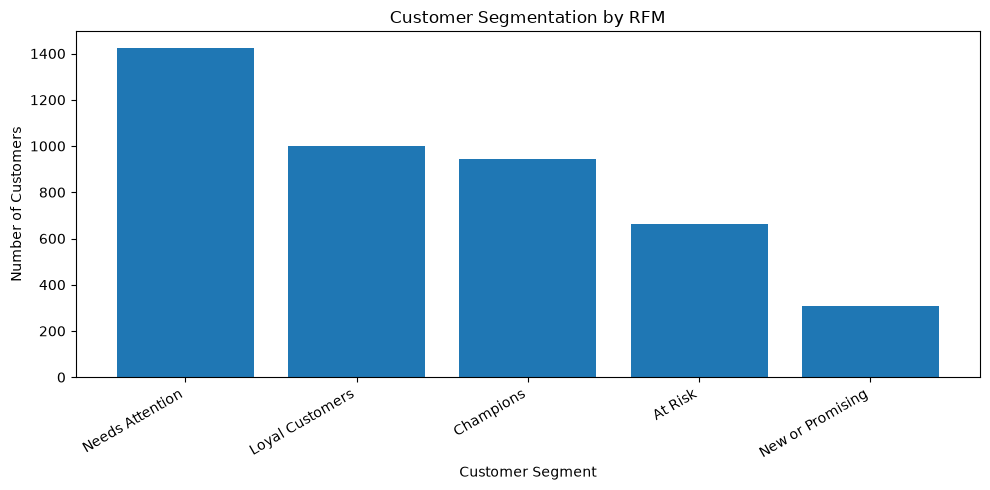

In [10]:

segment_counts = (
    rfm["Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customers")
)

display(segment_counts)

plt.figure(figsize=(10, 5))
plt.bar(
    segment_counts["Segment"],
    segment_counts["Customers"]
)

plt.title("Customer Segmentation by RFM")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [11]:

segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customers=("CustomerID", "nunique"),
        Average_Spend=("Monetary", "mean"),
        Total_Revenue=("Monetary", "sum"),
        Average_Orders=("Frequency", "mean"),
        Average_Recency_Days=("Recency", "mean")
    )
    .round(2)
    .sort_values("Total_Revenue", ascending=False)
)

display(segment_summary)


,Customers,Average_Spend,Total_Revenue,Average_Orders,Average_Recency_Days
Segment,,,,,
Champions,942,6091.24,5737952.12,11.20,12.50
Loyal Customers,1000,1500.69,1500694.33,3.75,33.32
At Risk,661,1246.46,823912.44,3.41,150.64
Needs Attention,1425,478.88,682410.56,1.12,176.24
New or Promising,310,458.84,142239.44,1.25,18.10


In [12]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

rfm.to_csv(output_dir / "customer_rfm.csv", index=False)
segment_summary.to_csv(output_dir / "segment_summary.csv")

print("RFM customer data saved successfully!")
print("Location:", output_dir.resolve())


RFM customer data saved successfully!
Location: D:\Programming\Python\Customer360\data\processed


In [1]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Save valid sales transactions for SQL analysis
sales_df.to_csv(
    output_dir / "sales_transactions.csv",
    index=False
)

# Save the RFM results again
rfm.to_csv(
    output_dir / "customer_rfm.csv",
    index=False
)

print("Files saved successfully!")

for file in output_dir.glob("*.csv"):
    print(f"{file.name}: {file.stat().st_size / (1024 * 1024):.2f} MB")


NameError: name 'sales_df' is not defined

In [2]:

import pandas as pd
from pathlib import Path

# Check whether the original dataset is available
print("Original dataset loaded:", "df" in globals())
print("Cleaned dataset available:", "clean_df" in globals())

# Recreate sales_df
if "clean_df" in globals():
    working_df = clean_df.copy()
elif "df" in globals():
    working_df = df.drop_duplicates().copy()
    working_df["InvoiceDate"] = pd.to_datetime(
        working_df["InvoiceDate"], errors="coerce"
    )
    working_df["IsCancelled"] = (
        working_df["InvoiceNo"].astype(str).str.startswith("C")
    )
    working_df["Revenue"] = (
        working_df["Quantity"] * working_df["UnitPrice"]
    )
else:
    raise NameError(
        "Neither df nor clean_df exists. Run the notebook's data-loading "
        "and cleaning cells first."
    )

sales_df = working_df[
    (~working_df["IsCancelled"]) &
    (working_df["Quantity"] > 0) &
    (working_df["UnitPrice"] > 0)
].copy()

print("Sales data recreated successfully!")
print("Rows:", len(sales_df))
display(sales_df.head())


Original dataset loaded: False
Cleaned dataset available: False


NameError: Neither df nor clean_df exists. Run the notebook's data-loading and cleaning cells first.

In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

file_path = Path("../data/raw/Online Retail.xlsx")

print("Looking for dataset at:", file_path.resolve())
print("File exists:", file_path.exists())

Looking for dataset at: D:\Programming\Python\Customer360\data\raw\Online Retail.xlsx
File exists: True


In [4]:
df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Original shape:", df.shape)

# Remove duplicate rows
clean_df = df.drop_duplicates().copy()

# Fix data types
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"], errors="coerce"
)

clean_df["CustomerID"] = clean_df["CustomerID"].astype("Int64")

# Remove rows missing essential transaction details
clean_df = clean_df.dropna(
    subset=[
        "InvoiceNo",
        "StockCode",
        "InvoiceDate",
        "Quantity",
        "UnitPrice"
    ]
).copy()

# Calculate revenue
clean_df["Revenue"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

# Identify cancelled invoices
clean_df["IsCancelled"] = (
    clean_df["InvoiceNo"].astype(str).str.startswith("C")
)

print("Cleaned shape:", clean_df.shape)
display(clean_df.head())

Dataset loaded successfully!
Original shape: (541909, 8)
Cleaned shape: (536641, 10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancelled
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False


In [5]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

sales_df.to_csv(
    output_dir / "sales_transactions.csv",
    index=False
)

print("Sales transactions saved successfully!")
print("Saved location:", output_dir.resolve())

NameError: name 'sales_df' is not defined

In [6]:

# Create sales_df from the cleaned dataset

sales_df = clean_df[
    (~clean_df["IsCancelled"]) &
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

print("Sales data created successfully!")
print("Total rows:", len(sales_df))
display(sales_df.head())


Sales data created successfully!
Total rows: 524878


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,IsCancelled
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False


In [7]:

from pathlib import Path

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

sales_df.to_csv(
    output_dir / "sales_transactions.csv",
    index=False
)

print("Sales transactions saved successfully!")
print("File location:", (output_dir / "sales_transactions.csv").resolve())


Sales transactions saved successfully!
File location: D:\Programming\Python\Customer360\data\processed\sales_transactions.csv


In [8]:

# Customer360: RFM Customer Segmentation

reference_date = sales_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

# Score customers from 1 to 5
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5, labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine the three scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

# Assign customer segments
rfm["Segment"] = np.select(
    [
        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] >= 4) &
        (rfm["M_Score"] >= 4),

        (rfm["R_Score"] >= 3) &
        (rfm["F_Score"] >= 3),

        (rfm["R_Score"] <= 2) &
        (rfm["F_Score"] >= 3),

        (rfm["R_Score"] >= 4) &
        (rfm["F_Score"] <= 2)
    ],
    [
        "Champions",
        "Loyal Customers",
        "At Risk",
        "New or Promising"
    ],
    default="Needs Attention"
)

print("RFM analysis completed!")
print("Total customers:", len(rfm))
display(rfm.head())


RFM analysis completed!
Total customers: 4338


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,5,115,Needs Attention
1,12347,2,7,4310.00,5,5,5,555,Champions
2,12348,75,4,1797.24,2,4,4,244,At Risk
3,12349,19,1,1757.55,4,1,4,414,New or Promising
4,12350,310,1,334.40,1,1,2,112,Needs Attention
